# Validación de calidad de datos — Caso 15 (Servicio Ciudadano 1800)
**Objetivo:** medir la calidad del dato antes (v0) y después (v1) de la limpieza, con los 5 KPI del Corte II, y demostrar que las políticas se ejecutan en código.
**Ciclo PHVA:** Planear (celda 2: KPI, metas, reglas) → Hacer (celdas 4 a 9: medir y probar) → Verificar (celdas 10 y 11) → Actuar (celdas 12 y 13).

In [1]:
# ============================================================
# Celda 1: Imports y configuración
# ============================================================
import sys, os, warnings
warnings.filterwarnings('ignore')
sys.path.append(os.path.abspath(os.path.join(os.getcwd(), '..')))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import chi2_contingency

try:
    from database import get_connection
except ImportError:
    from src.database import get_connection
from cargar_datos import cargar_dataset_recontacto

sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.size'] = 11
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 220)

os.makedirs('../informe_figuras', exist_ok=True)
os.makedirs('../informe_tablas', exist_ok=True)

def guardar(nombre):
    plt.savefig(f'../informe_figuras/CAL_{nombre}.png', dpi=150, bbox_inches='tight')

TABLA_V0 = 'dbo.stg_c15_v0'          # v0: dato crudo (todo como texto)
TABLA_V1 = 'dbo.hecho_interaccion'   # v1: dato limpio cargado al DW
TABLA_LOG = 'dbo.log_limpieza'       # bitácora de la limpieza R00-R09

print("✅ Librerías y configuración listas")

✅ Librerías y configuración listas


In [2]:
# ============================================================
# Celda 2: Los 5 KPI de calidad del Corte II (NO cambian) + catálogos y rangos
# ============================================================
KPI_CAL = [
    dict(id='KC1', nombre='Duplicados',                 dim='Unicidad',     regla='R-CAL-04', meta=1.0,   sentido='max',
         formula='registros con id repetido ÷ registros recibidos × 100'),
    dict(id='KC2', nombre='Completitud de canal',       dim='Completitud',  regla='R-CAL-03', meta=99.0,  sentido='min',
         formula='registros con canal identificado ÷ registros evaluados × 100'),
    dict(id='KC3', nombre='Consolidación del resultado', dim='Completitud', regla='R-CAL-01', meta=98.0,  sentido='min',
         formula='registros con recontacto_7_dias consolidado ÷ registros evaluados × 100'),
    dict(id='KC4', nombre='Normalización de motivo',    dim='Consistencia', regla='R-CAL-02', meta=100.0, sentido='min',
         formula='motivos que coinciden con el catálogo ÷ motivos registrados × 100'),
    dict(id='KC5', nombre='Valores fuera de rango',     dim='Validez',      regla='R-CAL-05/06', meta=0.5, sentido='max',
         formula='valores fuera de rango ÷ valores numéricos evaluados × 100'),
]
df_kpi_def = pd.DataFrame(KPI_CAL)
df_kpi_def['Meta'] = df_kpi_def.apply(lambda r: ('≤ ' if r.sentido == 'max' else '≥ ') + f"{r.meta:g}%", axis=1)
display(df_kpi_def[['id', 'nombre', 'dim', 'formula', 'Meta', 'regla']]
        .rename(columns={'id': 'KPI', 'nombre': 'Indicador', 'dim': 'Dimensión', 'formula': 'Fórmula', 'regla': 'Regla'}))

CATALOGO_MOTIVO = ['Consulta', 'Falla', 'Cobro', 'Solicitud', 'Queja']
RANGOS = {'dur': (30, 1800), 'esp': (0, 900), 'trans': (0, 4), 'prev': (0, 8)}   # diccionario del caso
NOMBRE_RANGO = {'dur': 'duracion_seg', 'esp': 'espera_seg', 'trans': 'transferencias', 'prev': 'casos_previos_30d'}
SLA_CARGA_DIAS = 30   # SUPUESTO declarado: una carga se considera tardía si pasan más de 30 días del contacto

# Nombres posibles de cada columna en la tabla v0 (se detectan solos)
CANDIDATOS = {
    'id': ['id_interaccion', 'codigo_interaccion'], 'fecha': ['fecha_contacto'], 'carga': ['fecha_carga'],
    'canal': ['canal'], 'motivo': ['motivo_contacto', 'motivo'], 'dur': ['duracion_seg'], 'esp': ['espera_seg'],
    'trans': ['transferencias'], 'prev': ['casos_previos_30d'], 'rec': ['recontacto_7_dias', 'recontacto'],
}
REQUERIDAS = ['id', 'canal', 'motivo', 'dur', 'esp', 'rec']

,KPI,Indicador,Dimensión,Fórmula,Meta,Regla
0,KC1,Duplicados,Unicidad,registros con id repetido ÷ registros recibido...,≤ 1%,R-CAL-04
1,KC2,Completitud de canal,Completitud,registros con canal identificado ÷ registros e...,≥ 99%,R-CAL-03
2,KC3,Consolidación del resultado,Completitud,registros con recontacto_7_dias consolidado ÷ ...,≥ 98%,R-CAL-01
3,KC4,Normalización de motivo,Consistencia,motivos que coinciden con el catálogo ÷ motivo...,≥ 100%,R-CAL-02
4,KC5,Valores fuera de rango,Validez,valores fuera de rango ÷ valores numéricos eva...,≤ 0.5%,R-CAL-05/06


### ✍️ ANÁLISIS DEL EQUIPO — Planear
- ¿Por qué estos 5 KPI y no otros? ¿Cada uno a qué dimensión de calidad responde?
- ¿Las metas (1%, 99%, 98%, 100%, 0.5%) son aterrizadas o ambiciosas? Justifíquenlas.
- Supuesto declarado: carga tardía = más de 30 días (SLA). ¿Lo respaldan o lo ajustan?

In [3]:
# ============================================================
# Celda 3: El validador de calidad (reglas reutilizables)
# Una regla devuelve True en los registros que la VIOLAN.
# ============================================================
def mapear_columnas(columnas):
    bajo = {c.lower(): c for c in columnas}
    mapa = {k: next((bajo[o] for o in ops if o in bajo), None) for k, ops in CANDIDATOS.items()}
    faltan = [k for k in REQUERIDAS if mapa[k] is None]
    return {k: v for k, v in mapa.items() if v}, faltan

def vacio(s):
    return s.isna() | s.astype(str).str.strip().str.lower().isin(['', 'nan', 'none', 'null', 'nat'])

def a_num(s):
    return pd.to_numeric(s, errors='coerce')

def a_fecha(s, formato):
    return pd.to_datetime(s.astype(str).str.strip().str[:10], format=formato, errors='coerce')

R_DUP, R_CANAL, R_RES, R_MOT = 'R-CAL-04 duplicado', 'R-CAL-03 canal sin dato', 'R-CAL-01 sin resultado', 'R-CAL-02 motivo no normalizado'
R_DUR, R_ESP = 'R-CAL-05 duración fuera de rango', 'R-CAL-06 espera fuera de rango'
R_TRA, R_PRE = 'Transferencias fuera de rango', 'Casos previos fuera de rango'
R_FAL, R_FEC, R_CAR = 'Faltante en variable numérica', 'Fecha en formato dd/MM/yyyy', 'Carga tardía o anterior al contacto'

def validar(d, c):
    """Aplica todas las reglas a un DataFrame d con el mapa de columnas c. Devuelve una tabla booleana de violaciones."""
    out = pd.DataFrame(index=d.index)
    out[R_DUP] = d[c['id']].duplicated(keep='first')
    canal = d[c['canal']]
    out[R_CANAL] = vacio(canal) | canal.astype(str).str.strip().str.lower().isin(['(sin dato)', 'sin dato'])
    out[R_RES] = vacio(d[c['rec']])
    mot = d[c['motivo']]
    out[R_MOT] = (~vacio(mot)) & (~mot.astype(str).isin(CATALOGO_MOTIVO))
    nombres = {'dur': R_DUR, 'esp': R_ESP, 'trans': R_TRA, 'prev': R_PRE}
    faltante = pd.Series(False, index=d.index)
    for k, regla in nombres.items():
        if k in c and c[k] in d.columns:
            x = a_num(d[c[k]]); lo, hi = RANGOS[k]
            out[regla] = x.notna() & ~x.between(lo, hi)
            faltante |= x.isna()
    out[R_FAL] = faltante
    if 'fecha' in c and 'carga' in c:
        f_std, f_alt = a_fecha(d[c['fecha']], '%Y-%m-%d'), a_fecha(d[c['fecha']], '%d/%m/%Y')
        out[R_FEC] = f_std.isna() & f_alt.notna()
        f = f_std.fillna(f_alt)
        l_std, l_alt = a_fecha(d[c['carga']], '%Y-%m-%d'), a_fecha(d[c['carga']], '%d/%m/%Y')
        lat = (l_std.fillna(l_alt) - f).dt.days
        out[R_CAR] = lat.notna() & ((lat < 0) | (lat > SLA_CARGA_DIAS))
    return out

def cumple(valor, meta, sentido):
    return valor >= meta if sentido == 'min' else valor <= meta

print("✅ Validador definido: reglas listas para v0 y v1")

✅ Validador definido: reglas listas para v0 y v1


In [4]:
# ============================================================
# Celda 4: Cargar v0 (crudo) y v1 (limpio) desde SQL Server + control de volumetría
# ============================================================
conn = get_connection()
v0 = pd.read_sql(f"SELECT * FROM {TABLA_V0}", conn)
hecho_n = int(pd.read_sql(f"SELECT COUNT(*) AS n FROM {TABLA_V1}", conn).iloc[0, 0])
log = pd.read_sql(f"SELECT * FROM {TABLA_LOG}", conn)
conn.close()
dm = cargar_dataset_recontacto()          # dataset analítico (lo que usa el modelo)

C, faltan = mapear_columnas(v0.columns)
print("=" * 70)
print("📥 CARGA DE v0 Y v1")
print("=" * 70)
print(f"   • v0 (stg_c15_v0, crudo)           : {len(v0):,} filas × {v0.shape[1]} columnas")
print(f"   • v1 cargado al DW (hecho_interaccion): {hecho_n:,} filas")
print(f"   • Dataset analítico (modelo)         : {len(dm):,} filas")
print(f"   • Columnas detectadas en v0          : {C}")
if faltan:
    raise ValueError(f"No encontré estas columnas en {TABLA_V0}: {faltan}. Columnas reales: {list(v0.columns)}")

print("\n📋 Bitácora de limpieza R00-R09 (log_limpieza) tal como quedó en el DW:")
display(log)

✅ Conexión exitosa a SQL Server
📊 CARGANDO DATASET DE RECONTACTO (KPI 1)
✅ Conexión exitosa a SQL Server
✅ Consulta ejecutada: 11,436 registros, 34 columnas

📏 Dimensiones: 11,436 filas × 34 columnas

🎯 Distribución del target:
es_recontacto
0    6687
1    4749
Name: count, dtype: int64

📈 Tasa de recontacto: 41.53%
📥 CARGA DE v0 Y v1
   • v0 (stg_c15_v0, crudo)           : 12,334 filas × 17 columnas
   • v1 cargado al DW (hecho_interaccion): 11,634 filas
   • Dataset analítico (modelo)         : 11,436 filas
   • Columnas detectadas en v0          : {'id': 'id_interaccion', 'fecha': 'fecha_contacto', 'carga': 'fecha_carga', 'canal': 'canal', 'motivo': 'motivo_contacto', 'dur': 'duracion_seg', 'esp': 'espera_seg', 'trans': 'transferencias', 'prev': 'casos_previos_30d', 'rec': 'recontacto_7_dias'}

📋 Bitácora de limpieza R00-R09 (log_limpieza) tal como quedó en el DW:


,id_log,fecha_ejecucion,regla,campo,accion,registros_afectados,registros_total,detalle
0,1,2026-11-04 10:47:27.245127,R00 Recepcion v0,(todos),Copia de trabajo; v0 intacto,12334,12334,stg_c15_v0 no se modifica
1,2,2026-11-04 10:47:27.335074,R01 Unicidad,id_interaccion,Eliminar copias; se conserva la primera,334,12334,Registros repetidos
2,3,2026-11-04 10:47:27.949059,R02 Formato de fecha,fecha_contacto,Convertir dd/MM/yyyy a yyyy-MM-dd,628,12000,Error de formato (mayo 2025)
3,4,2026-11-04 10:47:28.031272,R02b Fecha invalida,fecha_contacto,Rechazar (no recuperable),0,12000,Fecha no interpretable
4,5,2026-11-04 10:47:28.081223,R03 Etiquetas,motivo_contacto,Normalizar mayusculas al catalogo,136,12000,"COBRO/Cobro, QUEJA/Queja"
5,6,2026-11-04 10:47:28.147275,R03b Completitud canal,canal,Marcar como categoria Sin dato (no recuperable),316,12000,Canal ausente
6,7,2026-11-04 10:47:28.871968,R04 Rango,duracion_seg,Rechazar registro (30-1800),51,12000,Fuera de rango
7,8,2026-11-04 10:47:28.871968,R04 Rango,espera_seg,Rechazar registro (0-900),61,12000,Fuera de rango
8,9,2026-11-04 10:47:28.871968,R04 Rango,transferencias,Rechazar registro (0-4),55,12000,Fuera de rango
9,10,2026-11-04 10:47:28.871968,R04 Rango,casos_previos_30d,Rechazar registro (0-8),51,12000,Fuera de rango


In [5]:
# ============================================================
# Celda 5: KPI de calidad en v0 (AS-IS)
# ============================================================
V = validar(v0, C)
N0 = len(v0)

def kpis_v0(V, d, c):
    reg = (~vacio(d[c['motivo']]))
    num = [c[k] for k in RANGOS if k in c and c[k] in d.columns]
    evaluados = int(sum(a_num(d[x]).notna().sum() for x in num))
    fuera = int(sum(V[r].sum() for r in [R_DUR, R_ESP, R_TRA, R_PRE] if r in V))
    return {
        'KC1': V[R_DUP].mean() * 100,
        'KC2': 100 - V[R_CANAL].mean() * 100,
        'KC3': 100 - V[R_RES].mean() * 100,
        'KC4': (1 - V.loc[reg, R_MOT].mean()) * 100,
        'KC5': fuera / evaluados * 100,
    }

as_is = kpis_v0(V, v0, C)
filas = []
for k in KPI_CAL:
    v = as_is[k['id']]
    filas.append({'KPI': k['id'], 'Indicador': k['nombre'], 'Dimensión': k['dim'],
                  'Meta': ('≤ ' if k['sentido'] == 'max' else '≥ ') + f"{k['meta']:g}%",
                  'AS-IS (v0)': round(v, 2), 'Estado AS-IS': '✅ CUMPLE' if cumple(v, k['meta'], k['sentido']) else '❌ NO CUMPLE'})
df_asis = pd.DataFrame(filas)
print("=" * 70)
print(f"📊 KPI DE CALIDAD EN v0 (AS-IS) — {N0:,} registros recibidos")
print("=" * 70)
display(df_asis)
print(f"\n🎯 KPI que cumplen en v0: {(df_asis['Estado AS-IS'] == '✅ CUMPLE').sum()} de {len(df_asis)}")

📊 KPI DE CALIDAD EN v0 (AS-IS) — 12,334 registros recibidos


,KPI,Indicador,Dimensión,Meta,AS-IS (v0),Estado AS-IS
0,KC1,Duplicados,Unicidad,≤ 1%,2.71,❌ NO CUMPLE
1,KC2,Completitud de canal,Completitud,≥ 99%,97.39,❌ NO CUMPLE
2,KC3,Consolidación del resultado,Completitud,≥ 98%,98.37,✅ CUMPLE
3,KC4,Normalización de motivo,Consistencia,≥ 100%,98.87,❌ NO CUMPLE
4,KC5,Valores fuera de rango,Validez,≤ 0.5%,0.46,✅ CUMPLE



🎯 KPI que cumplen en v0: 2 de 5


### ✍️ ANÁLISIS DEL EQUIPO — Situación inicial (AS-IS)
- ¿Cuántos registros se analizaron y cuántos tenían incidencia? (Eddy: contar analizados / con incidencia / limpios.)
- ¿Qué KPI no cumplen en v0 y qué dimensión de calidad afectan?
- Si un KPI no cumple: ¿está mal el dato o la meta no era aterrizada?

In [6]:
# ============================================================
# Celda 6: Inventario de incidencias en v0 y diagrama de Pareto (regla 80/20)
# ============================================================
inv = pd.DataFrame({'Incidencia': V.columns, 'Registros': V.sum().values.astype(int)})
inv['% de v0'] = (inv['Registros'] / N0 * 100).round(2)
inv = inv[inv['Registros'] > 0].sort_values('Registros', ascending=False).reset_index(drop=True)
inv['% acumulado de incidencias'] = (inv['Registros'].cumsum() / inv['Registros'].sum() * 100).round(1)

con_incidencia = int(V.any(axis=1).sum())
print("=" * 70)
print("🔍 INVENTARIO DE INCIDENCIAS EN v0")
print("=" * 70)
display(inv)
print(f"\n   • Registros con al menos una incidencia : {con_incidencia:,} ({con_incidencia / N0:.2%})")
print(f"   • Registros sin ninguna incidencia      : {N0 - con_incidencia:,} ({(N0 - con_incidencia) / N0:.2%})")

fig, ax = plt.subplots(figsize=(12, 6))
ax.bar(inv['Incidencia'], inv['Registros'], color='#e67e22', edgecolor='black')
ax.set_ylabel('Registros afectados')
ax.set_title('Incidencias de calidad en v0 (Pareto)', fontweight='bold')
plt.setp(ax.get_xticklabels(), rotation=30, ha='right')
for i, v in enumerate(inv['Registros']):
    ax.text(i, v + max(inv['Registros']) * 0.01, f'{v:,}', ha='center', fontweight='bold')
ax2 = ax.twinx()
ax2.plot(inv['Incidencia'], inv['% acumulado de incidencias'], color='#2c3e50', marker='o')
ax2.set_ylim(0, 105); ax2.set_ylabel('% acumulado'); ax2.grid(False)
plt.tight_layout(); guardar('01_pareto_incidencias'); plt.show()

🔍 INVENTARIO DE INCIDENCIAS EN v0


,Incidencia,Registros,% de v0,% acumulado de incidencias
0,Carga tardía o anterior al contacto,645,5.23,25.3
1,Fecha en formato dd/MM/yyyy,637,5.16,50.3
2,R-CAL-04 duplicado,334,2.71,63.3
3,R-CAL-03 canal sin dato,322,2.61,76.0
4,R-CAL-01 sin resultado,201,1.63,83.8
5,R-CAL-02 motivo no normalizado,139,1.13,89.3
6,R-CAL-06 espera fuera de rango,68,0.55,92.0
7,Transferencias fuera de rango,55,0.45,94.1
8,R-CAL-05 duración fuera de rango,52,0.42,96.2
9,Casos previos fuera de rango,52,0.42,98.2



   • Registros con al menos una incidencia : 2,360 (19.13%)
   • Registros sin ninguna incidencia      : 9,974 (80.87%)


<Figure size 1200x600 with 2 Axes>

In [7]:
# ============================================================
# Celda 7: Bitácora oficial de incidencias (causa, riesgo, tratamiento, responsable)
# La causa es una HIPÓTESIS del equipo (viene del Marco V2) y debe confirmarse con Operaciones.
# ============================================================
def nivel(pct):
    return 'Alto' if pct >= 5 else 'Medio' if pct >= 1 else 'Bajo'

ficha = {
    R_DUP:   ('KC1', 'RG-04', 'Reintentos o reprocesos al integrar las fuentes sin control de unicidad', 'Deduplicar por id_interaccion (regla de unicidad)', 'Calidad (A) / Operaciones (R)'),
    R_CANAL: ('KC2', 'RG-03', 'Falla en la captura automática del canal de origen en el ACD', 'Campo obligatorio validado desde el origen', 'Operaciones (A/R)'),
    R_RES:   ('KC3', 'RG-01', 'El agente no registra o no consolida el resultado final en CRM', 'Excluir del modelo y documentar el criterio de consolidación', 'Calidad (A) / Operaciones (R)'),
    R_MOT:   ('KC4', 'RG-02', 'El IVR o el registro manual no usa un catálogo único', 'Normalizar contra el catálogo único de motivos', 'Calidad (A) / Operaciones (R)'),
    R_DUR:   ('KC5', 'R-CAL-05', 'Error de medición o captura de la duración', 'Validación de rango 30–1800 s', 'Operaciones (R) / Calidad (A)'),
    R_ESP:   ('KC5', 'R-CAL-06', 'Error de medición o captura de la espera', 'Validación de rango 0–900 s', 'Operaciones (R) / Calidad (A)'),
    R_TRA:   ('KC5', '—', 'Error de captura de transferencias', 'Validación de rango 0–4', 'Operaciones (R)'),
    R_PRE:   ('KC5', '—', 'Error en el cálculo del historial', 'Validación de rango 0–8', 'Operaciones (R)'),
    R_FAL:   ('—',   '—', 'Campo numérico sin valor o con texto', 'Revisar antes de cargar', 'Operaciones (R)'),
    R_FEC:   ('—',   '—', 'Carga desde una fuente con otro formato de fecha', 'Estandarizar a AAAA-MM-DD', 'Calidad (R)'),
    R_CAR:   ('—',   '—', 'Retraso en la carga o fecha de carga inconsistente', f'Control de oportunidad (SLA {SLA_CARGA_DIAS} días, supuesto)', 'Calidad (A) / TI (C)'),
}
filas = []
for i, r in inv.iterrows():
    kpi, rg, causa, trat, resp = ficha.get(r['Incidencia'], ('—', '—', '—', '—', '—'))
    filas.append({'ID': f'INC-CAL-{i + 1:03d}', 'Incidencia': r['Incidencia'], 'KPI': kpi, 'Riesgo': rg,
                  'Registros': r['Registros'], '% de v0': r['% de v0'], 'Nivel': nivel(r['% de v0']),
                  'Causa probable (hipótesis)': causa, 'Tratamiento': trat, 'Responsable (RACI)': resp})
bitacora = pd.DataFrame(filas)
print("=" * 70)
print("📋 BITÁCORA OFICIAL DE INCIDENCIAS DE CALIDAD")
print("=" * 70)
display(bitacora)
print("\nNivel según el % de v0 afectado: Alto ≥ 5% | Medio 1–5% | Bajo < 1%")

📋 BITÁCORA OFICIAL DE INCIDENCIAS DE CALIDAD


,ID,Incidencia,KPI,Riesgo,Registros,% de v0,Nivel,Causa probable (hipótesis),Tratamiento,Responsable (RACI)
0,INC-CAL-001,Carga tardía o anterior al contacto,—,—,645,5.23,Alto,Retraso en la carga o fecha de carga inconsist...,"Control de oportunidad (SLA 30 días, supuesto)",Calidad (A) / TI (C)
1,INC-CAL-002,Fecha en formato dd/MM/yyyy,—,—,637,5.16,Alto,Carga desde una fuente con otro formato de fecha,Estandarizar a AAAA-MM-DD,Calidad (R)
2,INC-CAL-003,R-CAL-04 duplicado,KC1,RG-04,334,2.71,Medio,Reintentos o reprocesos al integrar las fuente...,Deduplicar por id_interaccion (regla de unicidad),Calidad (A) / Operaciones (R)
3,INC-CAL-004,R-CAL-03 canal sin dato,KC2,RG-03,322,2.61,Medio,Falla en la captura automática del canal de or...,Campo obligatorio validado desde el origen,Operaciones (A/R)
4,INC-CAL-005,R-CAL-01 sin resultado,KC3,RG-01,201,1.63,Medio,El agente no registra o no consolida el result...,Excluir del modelo y documentar el criterio de...,Calidad (A) / Operaciones (R)
5,INC-CAL-006,R-CAL-02 motivo no normalizado,KC4,RG-02,139,1.13,Medio,El IVR o el registro manual no usa un catálogo...,Normalizar contra el catálogo único de motivos,Calidad (A) / Operaciones (R)
6,INC-CAL-007,R-CAL-06 espera fuera de rango,KC5,R-CAL-06,68,0.55,Bajo,Error de medición o captura de la espera,Validación de rango 0–900 s,Operaciones (R) / Calidad (A)
7,INC-CAL-008,Transferencias fuera de rango,KC5,—,55,0.45,Bajo,Error de captura de transferencias,Validación de rango 0–4,Operaciones (R)
8,INC-CAL-009,R-CAL-05 duración fuera de rango,KC5,R-CAL-05,52,0.42,Bajo,Error de medición o captura de la duración,Validación de rango 30–1800 s,Operaciones (R) / Calidad (A)
9,INC-CAL-010,Casos previos fuera de rango,KC5,—,52,0.42,Bajo,Error en el cálculo del historial,Validación de rango 0–8,Operaciones (R)



Nivel según el % de v0 afectado: Alto ≥ 5% | Medio 1–5% | Bajo < 1%


### ✍️ ANÁLISIS DEL EQUIPO — Problemas y causa
- Por cada problema (duplicados, incompletos, fuera de rango, no estandarizados): ¿cuál es la causa y **cómo la verificaron**? (Eddy: no basta con suponerla.)
- ¿Qué hipótesis de la columna "Causa probable" confirmaron y con quién?
- ¿Qué problema es el más grave por impacto y no solo por cantidad?

In [8]:
# ============================================================
# Celda 7b: Verificación cruzada: validador del notebook vs log_limpieza del DW
# ============================================================
nd = ~V[R_DUP]   # el log cuenta sobre registros ya sin duplicados (excepto R01)

def n_log(prefijo, campo=None):
    f = log['regla'].astype(str).str.startswith(prefijo)
    if campo:
        f &= log['campo'].astype(str).str.strip() == campo
    return int(log.loc[f, 'registros_afectados'].sum())

def n_val(regla, solo_nd=True):
    return int(V.loc[nd, regla].sum()) if solo_nd else int(V[regla].sum())

verif = pd.DataFrame([
    ('R01 Unicidad',            'Duplicados',                    n_val(R_DUP, False),  n_log('R01')),
    ('R02 Formato de fecha',    'Fecha dd/MM/yyyy',              n_val(R_FEC),         n_log('R02 ')),
    ('R03 Etiquetas',           'Motivo no normalizado',         n_val(R_MOT),         n_log('R03 ')),
    ('R03b Completitud canal',  'Canal sin dato',                n_val(R_CANAL),       n_log('R03b')),
    ('R04 Rango',               'Duración fuera de rango',       n_val(R_DUR),         n_log('R04', 'duracion_seg')),
    ('R04 Rango',               'Espera fuera de rango',         n_val(R_ESP),         n_log('R04', 'espera_seg')),
    ('R04 Rango',               'Transferencias fuera de rango', n_val(R_TRA),         n_log('R04', 'transferencias')),
    ('R04 Rango',               'Casos previos fuera de rango',  n_val(R_PRE),         n_log('R04', 'casos_previos_30d')),
    ('R06 Resultado',           'Sin resultado consolidado',     n_val(R_RES),         n_log('R06')),
    ('R07 Oportunidad',         'Carga tardía',                  n_val(R_CAR),         n_log('R07')),
], columns=['Regla del log (DW)', 'Incidencia del validador', 'Validador (notebook)', 'Log del DW'])
verif['Diferencia'] = verif['Validador (notebook)'] - verif['Log del DW']
verif['Lectura'] = np.where(verif['Diferencia'] == 0, 'Coincide', 'Difiere (ver nota)')
print("=" * 70)
print("🔎 VERIFICACIÓN CRUZADA: validador del notebook vs log_limpieza del DW")
print("=" * 70)
display(verif)
print("\nNota: R06 y R07 el log las mide DESPUÉS de rechazar registros (R04/R05c); el validador las mide sobre todo v0 sin duplicados.")
print("Por eso pueden diferir levemente. Las reglas R01 a R04 deben coincidir o explicarse.")

🔎 VERIFICACIÓN CRUZADA: validador del notebook vs log_limpieza del DW


,Regla del log (DW),Incidencia del validador,Validador (notebook),Log del DW,Diferencia,Lectura
0,R01 Unicidad,Duplicados,334,334,0,Coincide
1,R02 Formato de fecha,Fecha dd/MM/yyyy,628,628,0,Coincide
2,R03 Etiquetas,Motivo no normalizado,136,136,0,Coincide
3,R03b Completitud canal,Canal sin dato,316,316,0,Coincide
4,R04 Rango,Duración fuera de rango,51,51,0,Coincide
5,R04 Rango,Espera fuera de rango,61,61,0,Coincide
6,R04 Rango,Transferencias fuera de rango,55,55,0,Coincide
7,R04 Rango,Casos previos fuera de rango,51,51,0,Coincide
8,R06 Resultado,Sin resultado consolidado,199,198,1,Difiere (ver nota)
9,R07 Oportunidad,Carga tardía,634,614,20,Difiere (ver nota)



Nota: R06 y R07 el log las mide DESPUÉS de rechazar registros (R04/R05c); el validador las mide sobre todo v0 sin duplicados.
Por eso pueden diferir levemente. Las reglas R01 a R04 deben coincidir o explicarse.


⚖️ CONCILIACIÓN DEL UNIVERSO


,Concepto,Registros,% del universo
0,Registros recibidos en v0,12334,100.00
1,− Duplicados eliminados,334,2.71
2,− Rechazados por las reglas de limpieza,366,2.97
3,= Cargados al DW (v1),11634,94.32
4,− Sin resultado consolidado (excluidos del mod...,198,1.61
5,= Usados por el modelo,11436,92.72



   Cuadre: 334 + 366 + 198 + 11,436 = 12,334  →  ✅ cuadra con 12,334
   Cobertura: el modelo trabaja con el 92.72% del universo recibido; el 7.28% restante quedó fuera.

🔎 Verificación contra la corrida anterior de la limpieza:
   ✅ recibidos   esperado 12,334 | obtenido 12,334
   ✅ duplicados  esperado 334 | obtenido 334
   ✅ rechazados  esperado 366 | obtenido 366
   ✅ cargados    esperado 11,634 | obtenido 11,634
   ✅ usados      esperado 11,436 | obtenido 11,436

   Rechazados: 218 por rango (R04) + 148 no recuperables (R05c) = 366  →  ✅ cuadra con 366


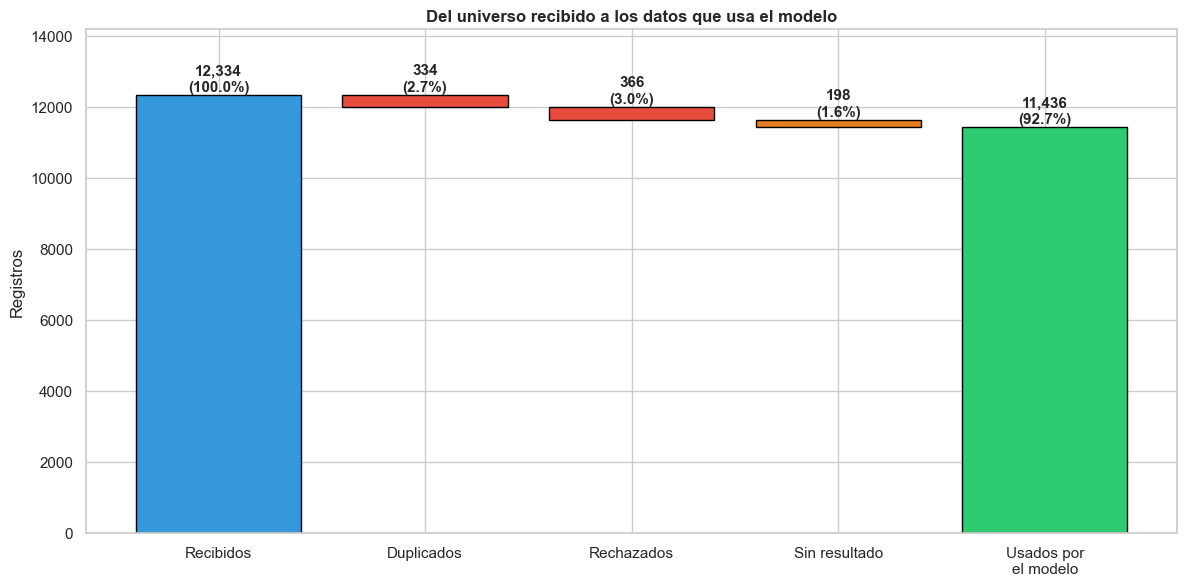

In [9]:
# ============================================================
# Celda 8: Conciliación del universo (qué entró, qué salió y por qué)
# ============================================================
dup = int(V[R_DUP].sum())
rechazados = N0 - dup - hecho_n          # no son duplicados ni quedaron cargados en el DW
sin_resultado = hecho_n - len(dm)         # cargados, pero sin resultado consolidado
usados = len(dm)
cuadra = (dup + rechazados + sin_resultado + usados) == N0

conc = pd.DataFrame([
    {'Concepto': 'Registros recibidos en v0', 'Registros': N0},
    {'Concepto': '− Duplicados eliminados', 'Registros': dup},
    {'Concepto': '− Rechazados por las reglas de limpieza', 'Registros': rechazados},
    {'Concepto': '= Cargados al DW (v1)', 'Registros': hecho_n},
    {'Concepto': '− Sin resultado consolidado (excluidos del modelo)', 'Registros': sin_resultado},
    {'Concepto': '= Usados por el modelo', 'Registros': usados},
])
conc['% del universo'] = (conc['Registros'] / N0 * 100).round(2)
print("=" * 70)
print("⚖️ CONCILIACIÓN DEL UNIVERSO")
print("=" * 70)
display(conc)
print(f"\n   Cuadre: {dup:,} + {rechazados:,} + {sin_resultado:,} + {usados:,} = {dup + rechazados + sin_resultado + usados:,}  →  {'✅ cuadra con ' + format(N0, ',') if cuadra else '⚠️ NO cuadra con ' + format(N0, ',')}")
print(f"   Cobertura: el modelo trabaja con el {usados / N0:.2%} del universo recibido; el {1 - usados / N0:.2%} restante quedó fuera.")

ESPERADO = {'recibidos': 12334, 'duplicados': 334, 'rechazados': 366, 'cargados': 11634, 'usados': 11436}
real = {'recibidos': N0, 'duplicados': dup, 'rechazados': rechazados, 'cargados': hecho_n, 'usados': usados}
print("\n🔎 Verificación contra la corrida anterior de la limpieza:")
for k, v in ESPERADO.items():
    print(f"   {'✅' if real[k] == v else '⚠️'} {k:11s} esperado {v:,} | obtenido {real[k]:,}")

# --- FIX Cloud IA: descomposición de los 366 rechazados usando el log del DW ---
rech_rango = int(log.loc[log['regla'].str.startswith('R04'), 'registros_afectados'].sum())
rech_nr = int(log.loc[log['regla'].str.startswith('R05c'), 'registros_afectados'].sum())
print(f"\n   Rechazados: {rech_rango} por rango (R04) + {rech_nr} no recuperables (R05c) = {rech_rango + rech_nr}  →  {'✅ cuadra con ' + str(rechazados) if rech_rango + rech_nr == rechazados else '⚠️ no cuadra con ' + str(rechazados)}")
# ---------------------------------------------------------------------------

pasos = ['Recibidos', 'Duplicados', 'Rechazados', 'Sin resultado', 'Usados por\nel modelo']
vals = [N0, -dup, -rechazados, -sin_resultado, usados]
base, acum = [], N0
for i, v in enumerate(vals):
    if i == 0 or i == len(vals) - 1:
        base.append(0)
    else:
        acum += v; base.append(acum)
alturas = [abs(v) for v in vals]
colores = ['#3498db', '#e74c3c', '#e74c3c', '#e67e22', '#2ecc71']
fig, ax = plt.subplots(figsize=(12, 6))
ax.bar(pasos, alturas, bottom=base, color=colores, edgecolor='black')
for i, (a, b) in enumerate(zip(alturas, base)):
    ax.text(i, a + b + N0 * 0.01, f"{a:,}\n({a / N0:.1%})", ha='center', fontweight='bold')
ax.set_ylim(0, N0 * 1.15); ax.set_ylabel('Registros')
ax.set_title('Del universo recibido a los datos que usa el modelo', fontweight='bold')
plt.tight_layout(); guardar('02_cascada_universo'); plt.show()

In [10]:
# ============================================================
# Celda 9: Pruebas reproducibles del validador (registros válidos e inválidos)
# Se usa EXACTAMENTE la misma función validar() que se aplicó a v0.
# ============================================================
def fila(c_id, canal='Chat', motivo='Falla', dur=600, esp=120, rec='1'):
    return {C['id']: c_id, C['canal']: canal, C['motivo']: motivo, C['dur']: dur, C['esp']: esp, C['rec']: rec}

casos = [
    ('T01', 'Registro válido típico',            fila('P01'),                     []),
    ('T02', 'Duración en el límite inferior (30)', fila('P02', dur=30),             []),
    ('T03', 'Duración bajo el límite (29)',        fila('P03', dur=29),             [R_DUR]),
    ('T04', 'Duración en el límite superior (1800)', fila('P04', dur=1800),         []),
    ('T05', 'Duración sobre el límite (1801)',     fila('P05', dur=1801),           [R_DUR]),
    ('T06', 'Espera cero (0)',                     fila('P06', esp=0),              []),
    ('T07', 'Espera negativa (−1)',                fila('P07', esp=-1),             [R_ESP]),
    ('T08', 'Espera en el límite (900)',           fila('P08', esp=900),            []),
    ('T09', 'Espera sobre el límite (901)',        fila('P09', esp=901),            [R_ESP]),
    ('T10', 'Motivo en mayúsculas (COBRO)',        fila('P10', motivo='COBRO'),     [R_MOT]),
    ('T11', 'Canal "(sin dato)"',                  fila('P11', canal='(sin dato)'), [R_CANAL]),
    ('T12', 'Resultado sin consolidar (vacío)',    fila('P12', rec=''),             [R_RES]),
    ('T13', 'Primera aparición de un id',          fila('P13'),                     []),
    ('T14', 'Segunda aparición del mismo id',      fila('P13'),                     [R_DUP]),
]
df_t = pd.DataFrame([c[2] for c in casos])
res_t = validar(df_t, {k: C[k] for k in REQUERIDAS})
cols_eval = [R_DUP, R_CANAL, R_RES, R_MOT, R_DUR, R_ESP]

filas = []
for i, (tid, desc, _, esperado) in enumerate(casos):
    obtenido = [r for r in cols_eval if res_t.loc[i, r]]
    filas.append({'Prueba': tid, 'Caso': desc, 'Resultado esperado': ', '.join(esperado) or 'Válido',
                  'Resultado obtenido': ', '.join(obtenido) or 'Válido',
                  'Estado': '✅ PASA' if set(esperado) == set(obtenido) else '❌ FALLA'})
df_pruebas = pd.DataFrame(filas)
print("=" * 70)
print("🧪 PRUEBAS REPRODUCIBLES DEL VALIDADOR")
print("=" * 70)
display(df_pruebas)
print(f"\n   Pruebas superadas: {(df_pruebas['Estado'] == '✅ PASA').sum()} de {len(df_pruebas)}")
assert (df_pruebas['Estado'] == '✅ PASA').all(), "Alguna prueba del validador falló: revisar las reglas"

🧪 PRUEBAS REPRODUCIBLES DEL VALIDADOR


,Prueba,Caso,Resultado esperado,Resultado obtenido,Estado
0,T01,Registro válido típico,Válido,Válido,✅ PASA
1,T02,Duración en el límite inferior (30),Válido,Válido,✅ PASA
2,T03,Duración bajo el límite (29),R-CAL-05 duración fuera de rango,R-CAL-05 duración fuera de rango,✅ PASA
3,T04,Duración en el límite superior (1800),Válido,Válido,✅ PASA
4,T05,Duración sobre el límite (1801),R-CAL-05 duración fuera de rango,R-CAL-05 duración fuera de rango,✅ PASA
5,T06,Espera cero (0),Válido,Válido,✅ PASA
6,T07,Espera negativa (−1),R-CAL-06 espera fuera de rango,R-CAL-06 espera fuera de rango,✅ PASA
7,T08,Espera en el límite (900),Válido,Válido,✅ PASA
8,T09,Espera sobre el límite (901),R-CAL-06 espera fuera de rango,R-CAL-06 espera fuera de rango,✅ PASA
9,T10,Motivo en mayúsculas (COBRO),R-CAL-02 motivo no normalizado,R-CAL-02 motivo no normalizado,✅ PASA



   Pruebas superadas: 14 de 14


### ✍️ ANÁLISIS DEL EQUIPO — Gobierno y calidad
- Gobierno = políticas programadas + pruebas + auditoría. ¿Dónde se ve cada una en este notebook?
- ¿Qué casos de frontera (30, 1800, 0, 900) probaron y por qué importan?
- ¿Qué pasaría si una de las pruebas fallara en una carga real?

📊 KPI DE CALIDAD: AS-IS (v0) vs TO-BE (v1)


,KPI,Indicador,Meta,AS-IS (v0),Estado AS-IS,TO-BE (v1),Estado TO-BE,Cambio (pts),Efecto
0,KC1,Duplicados,≤ 1%,2.71,❌,0.00,✅,-2.71,Mejora
1,KC2,Completitud de canal,≥ 99%,97.39,❌,97.37,❌,-0.02,Empeora
2,KC3,Consolidación del resultado,≥ 98%,98.37,✅,98.30,✅,-0.07,Empeora
3,KC4,Normalización de motivo,≥ 100%,98.87,❌,100.00,✅,1.13,Mejora
4,KC5,Valores fuera de rango,≤ 0.5%,0.46,✅,0.00,✅,-0.46,Mejora



   Cumplen en v0: 2 de 5 | Cumplen en v1: 4 de 5
   ⚠️ Recordatorio: v1 cumple sobre lo que quedó; el 7.28% del universo quedó fuera (ver conciliación).
   Nota: 'Efecto' se calcula según el sentido de la meta. En KC1/KC5 bajar es mejora; en KC2/KC3/KC4 subir es mejora.


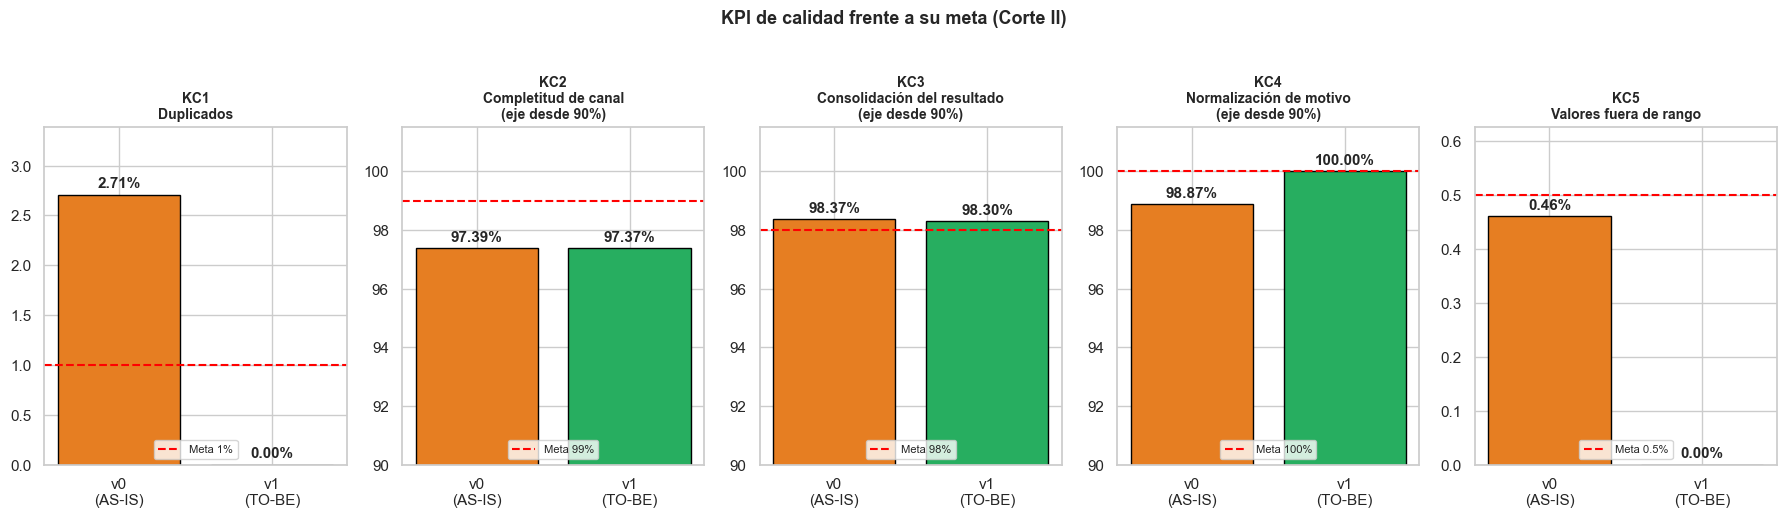

In [11]:
# ============================================================
# Celda 10: KPI de calidad en v1 (TO-BE) y comparación contra la meta
# v1 se mide sobre el dataset analítico (n = registros del modelo); KC3 sobre los cargados al DW.
# ============================================================
rangos_dm = {'duracion_seg': RANGOS['dur'], 'espera_seg': RANGOS['esp'],
             'transferencias': RANGOS['trans'], 'casos_previos_30d': RANGOS['prev']}
motivo_cols = [x for x in dm.columns if x.startswith('motivo_')]
evaluados = fuera = 0
for col, (lo, hi) in rangos_dm.items():
    if col in dm.columns:
        evaluados += dm[col].notna().sum()
        fuera += int((~dm[col].between(lo, hi) & dm[col].notna()).sum())

to_be = {
    'KC1': dm['id_interaccion'].duplicated().mean() * 100,
    'KC2': (1 - dm['canal_sin_dato'].mean()) * 100,
    'KC3': usados / hecho_n * 100,
    'KC4': (dm[motivo_cols].sum(axis=1) == 1).mean() * 100,
    'KC5': fuera / evaluados * 100,
}
filas = []
for k in KPI_CAL:
    a, b = as_is[k['id']], to_be[k['id']]
    delta_dir = (b - a) * (1 if k['sentido'] == 'min' else -1)
    filas.append({'KPI': k['id'], 'Indicador': k['nombre'],
                  'Meta': ('≤ ' if k['sentido'] == 'max' else '≥ ') + f"{k['meta']:g}%",
                  'AS-IS (v0)': round(a, 2), 'Estado AS-IS': '✅' if cumple(a, k['meta'], k['sentido']) else '❌',
                  'TO-BE (v1)': round(b, 2), 'Estado TO-BE': '✅' if cumple(b, k['meta'], k['sentido']) else '❌',
                  'Cambio (pts)': round(b - a, 2),
                  'Efecto': 'Mejora' if delta_dir > 0.005 else 'Empeora' if delta_dir < -0.005 else 'Sin cambio'})
df_cmp = pd.DataFrame(filas)
print("=" * 70)
print("📊 KPI DE CALIDAD: AS-IS (v0) vs TO-BE (v1)")
print("=" * 70)
display(df_cmp)
print(f"\n   Cumplen en v0: {(df_cmp['Estado AS-IS'] == '✅').sum()} de {len(df_cmp)} | Cumplen en v1: {(df_cmp['Estado TO-BE'] == '✅').sum()} de {len(df_cmp)}")
print(f"   ⚠️ Recordatorio: v1 cumple sobre lo que quedó; el {1 - usados / N0:.2%} del universo quedó fuera (ver conciliación).")
print("   Nota: 'Efecto' se calcula según el sentido de la meta. En KC1/KC5 bajar es mejora; en KC2/KC3/KC4 subir es mejora.")

fig, axes = plt.subplots(1, len(KPI_CAL), figsize=(18, 5))
for ax, k in zip(axes, KPI_CAL):
    a, b = as_is[k['id']], to_be[k['id']]
    ax.bar(['v0\n(AS-IS)', 'v1\n(TO-BE)'], [a, b], color=['#e67e22', '#27ae60'], edgecolor='black')
    ax.axhline(k['meta'], color='red', ls='--', label=f"Meta {k['meta']:g}%")
    if k['sentido'] == 'max':
        lo, top = 0, max(a, b, k['meta']) * 1.25
        sub = ''
    else:
        lo, top = 90, 101.5
        sub = '\n(eje desde 90%)'
    ax.set_ylim(lo, top)
    ax.set_title(f"{k['id']}\n{k['nombre']}{sub}", fontsize=10, fontweight='bold')
    for i, v in enumerate([a, b]):
        ax.text(i, max(v, lo) + (top - lo) * 0.02, f'{v:.2f}%', ha='center', fontweight='bold')
    ax.legend(fontsize=8, loc='lower center')
plt.suptitle('KPI de calidad frente a su meta (Corte II)', fontsize=13, fontweight='bold', y=1.03)
plt.tight_layout(); guardar('03_kpi_asis_tobe'); plt.show()

🔬 ¿LOS REGISTROS CON INCIDENCIA SE COMPORTAN DISTINTO? (prueba chi-cuadrado)


,Grupo,n con incidencia,recontacto con incidencia %,n sin incidencia,recontacto sin incidencia %,p-valor,Diferencia (pts),¿Significativa? (p < 0.05)
0,Cualquier incidencia,1827,40.78,9974,41.65,0.5036,-0.87,No
1,R-CAL-03 canal sin dato,308,44.81,11493,41.43,0.2587,3.38,No
2,R-CAL-02 motivo no normalizado,135,39.26,11666,41.54,0.6550,-2.28,No
3,R-CAL-05 duración fuera de rango,51,37.25,11750,41.53,0.6340,-4.28,No
4,R-CAL-06 espera fuera de rango,61,39.34,11740,41.52,0.8302,-2.18,No
5,Transferencias fuera de rango,55,30.91,11746,41.56,0.1436,-10.65,No
6,Casos previos fuera de rango,51,41.18,11750,41.51,1.0000,-0.34,No
7,Faltante en variable numérica,46,52.17,11755,41.47,0.1867,10.70,No
8,Fecha en formato dd/MM/yyyy,616,39.45,11185,41.63,0.3046,-2.18,No
9,Carga tardía o anterior al contacto,618,40.61,11183,41.56,0.6717,-0.95,No



Lectura: p < 0.05 indica que la tasa de recontacto de los registros con incidencia difiere de la de los limpios.
Si no difiere, dejarlos fuera cambia poco el resultado; si difiere, el modelo pudo quedar sesgado.


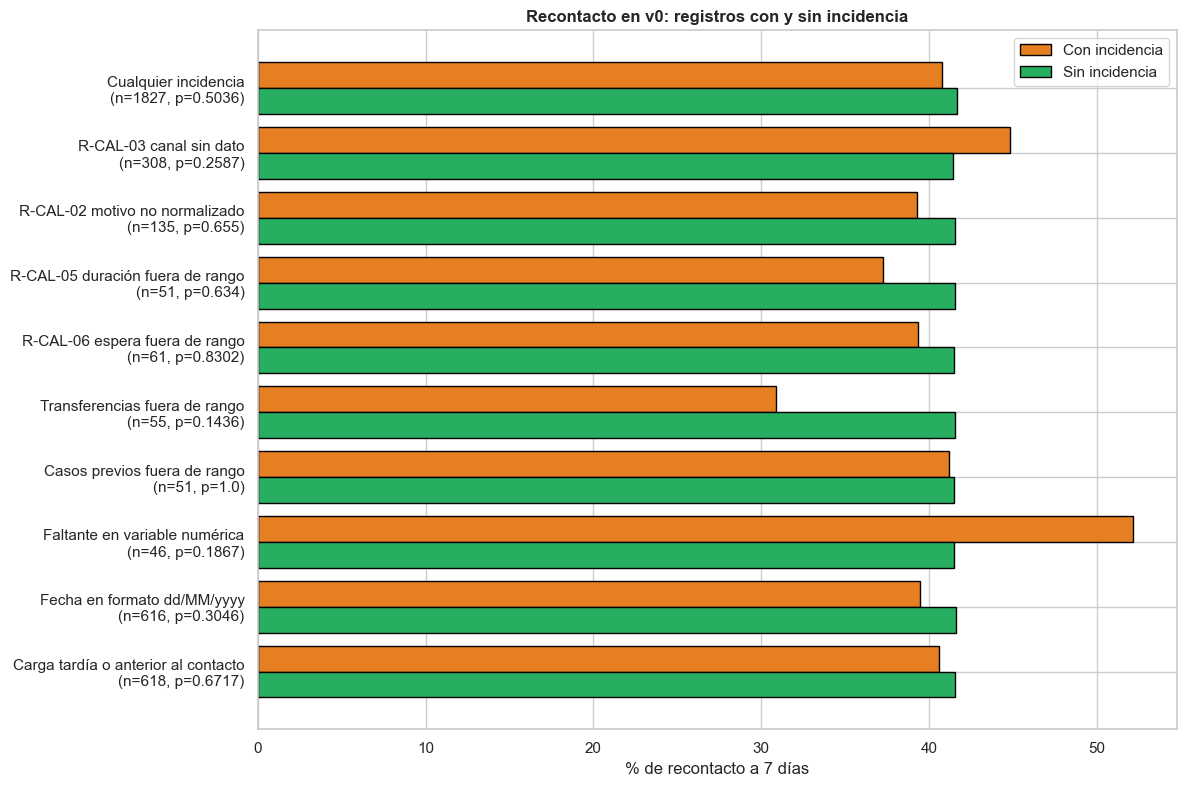

In [12]:
# ============================================================
# Celda 11: ¿Es significativo lo que quedó pendiente? (recontacto con y sin incidencia en v0)
# ============================================================
rec_num = a_num(v0[C['rec']])
base_ok = rec_num.notna() & ~V[R_DUP]                       # con resultado y sin duplicar
excluir = [R_DUP, R_RES]
tipos = [c for c in V.columns if c not in excluir and V.loc[base_ok, c].sum() >= 30]
algun = V.loc[:, [c for c in V.columns if c not in excluir]].any(axis=1)

def comparar(mask_inc):
    t = pd.crosstab(mask_inc[base_ok], rec_num[base_ok])
    if t.shape != (2, 2):
        return None
    chi2, p, _, _ = chi2_contingency(t)
    return {'n con incidencia': int(t.loc[True].sum()), 'recontacto con incidencia %': t.loc[True, 1.0] / t.loc[True].sum() * 100,
            'n sin incidencia': int(t.loc[False].sum()), 'recontacto sin incidencia %': t.loc[False, 1.0] / t.loc[False].sum() * 100,
            'p-valor': p}

filas = []
r = comparar(algun)
if r: filas.append({'Grupo': 'Cualquier incidencia', **r})
for c in tipos:
    r = comparar(V[c])
    if r: filas.append({'Grupo': c, **r})
df_sig = pd.DataFrame(filas)
if len(df_sig):
    df_sig['Diferencia (pts)'] = (df_sig['recontacto con incidencia %'] - df_sig['recontacto sin incidencia %']).round(2)
    df_sig['¿Significativa? (p < 0.05)'] = np.where(df_sig['p-valor'] < 0.05, 'Sí', 'No')
    for c in ['recontacto con incidencia %', 'recontacto sin incidencia %']:
        df_sig[c] = df_sig[c].round(2)
    df_sig['p-valor'] = df_sig['p-valor'].round(4)
print("=" * 70)
print("🔬 ¿LOS REGISTROS CON INCIDENCIA SE COMPORTAN DISTINTO? (prueba chi-cuadrado)")
print("=" * 70)
display(df_sig)
print("\nLectura: p < 0.05 indica que la tasa de recontacto de los registros con incidencia difiere de la de los limpios.")
print("Si no difiere, dejarlos fuera cambia poco el resultado; si difiere, el modelo pudo quedar sesgado.")

if len(df_sig):
    fig, ax = plt.subplots(figsize=(12, max(5, len(df_sig) * 0.8)))
    y = np.arange(len(df_sig))
    ax.barh(y - 0.2, df_sig['recontacto con incidencia %'], 0.4, label='Con incidencia', color='#e67e22', edgecolor='black')
    ax.barh(y + 0.2, df_sig['recontacto sin incidencia %'], 0.4, label='Sin incidencia', color='#27ae60', edgecolor='black')
    ax.set_yticks(y)
    ax.set_yticklabels([f"{g}\n(n={n}, p={p})" for g, n, p in zip(df_sig['Grupo'], df_sig['n con incidencia'], df_sig['p-valor'])])
    ax.invert_yaxis()
    ax.set_xlabel('% de recontacto a 7 días'); ax.legend()
    ax.set_title('Recontacto en v0: registros con y sin incidencia', fontweight='bold')
    plt.tight_layout(); guardar('04_significancia_residual'); plt.show()

### ✍️ ANÁLISIS DEL EQUIPO — Residual y significancia (lo que más pidió Eddy)
- No digan "100% limpio": ¿qué residual queda en v1 y cuánto del universo quedó fuera?
- "¿Ese 5% es significativo?" Usen la tabla de chi-cuadrado: ¿los registros con incidencia se comportan distinto?
- ¿Lo que queda permite implementar otras políticas? ¿Cuáles?
- Si un KPI no cumplió (ej. canal o consolidación): ¿falla el análisis o la meta no era aterrizada?
- Accuracy vs AUC: ¿por qué el modelo sigue siendo viable con este residual?

In [13]:
# ============================================================
# Celda 12: Política → regla → control → evidencia (políticas aplicadas en el validador)
# ============================================================
def n(regla):
    return int(V[regla].sum()) if regla in V else 0

politicas = pd.DataFrame([
    {'Política': 'POL-CAL-01', 'Regla': 'R-CAL-01 Resultado consolidado',      'Control (validación)': 'vacio(recontacto_7_dias)',        'Incidencias en v0': n(R_RES),    'Responsable': 'Calidad'},
    {'Política': 'POL-CAL-01', 'Regla': 'R-CAL-02 Motivo en catálogo',         'Control (validación)': 'motivo ∉ catálogo exacto',        'Incidencias en v0': n(R_MOT),    'Responsable': 'Calidad'},
    {'Política': 'POL-CAL-01', 'Regla': 'R-CAL-03 Canal siempre registrado',   'Control (validación)': 'canal vacío o "(sin dato)"',      'Incidencias en v0': n(R_CANAL),  'Responsable': 'Operaciones'},
    {'Política': 'POL-CAL-01', 'Regla': 'R-CAL-04 Id único',                   'Control (validación)': 'id duplicado (conserva el primero)', 'Incidencias en v0': n(R_DUP),  'Responsable': 'Calidad'},
    {'Política': 'POL-CAL-01', 'Regla': 'R-CAL-05 Duración 30–1800 s',         'Control (validación)': 'valor fuera de rango',            'Incidencias en v0': n(R_DUR),    'Responsable': 'Operaciones'},
    {'Política': 'POL-CAL-01', 'Regla': 'R-CAL-06 Espera 0–900 s',             'Control (validación)': 'valor fuera de rango',            'Incidencias en v0': n(R_ESP),    'Responsable': 'Operaciones'},
])
politicas['Evidencia'] = 'validar() + bitácora + pruebas T01–T14'
print("=" * 70)
print("📜 POLÍTICAS, REGLAS Y CONTROLES CON SU EVIDENCIA")
print("=" * 70)
display(politicas)

📜 POLÍTICAS, REGLAS Y CONTROLES CON SU EVIDENCIA


,Política,Regla,Control (validación),Incidencias en v0,Responsable,Evidencia
0,POL-CAL-01,R-CAL-01 Resultado consolidado,vacio(recontacto_7_dias),201,Calidad,validar() + bitácora + pruebas T01–T14
1,POL-CAL-01,R-CAL-02 Motivo en catálogo,motivo ∉ catálogo exacto,139,Calidad,validar() + bitácora + pruebas T01–T14
2,POL-CAL-01,R-CAL-03 Canal siempre registrado,"canal vacío o ""(sin dato)""",322,Operaciones,validar() + bitácora + pruebas T01–T14
3,POL-CAL-01,R-CAL-04 Id único,id duplicado (conserva el primero),334,Calidad,validar() + bitácora + pruebas T01–T14
4,POL-CAL-01,R-CAL-05 Duración 30–1800 s,valor fuera de rango,52,Operaciones,validar() + bitácora + pruebas T01–T14
5,POL-CAL-01,R-CAL-06 Espera 0–900 s,valor fuera de rango,68,Operaciones,validar() + bitácora + pruebas T01–T14


In [14]:
# ============================================================
# Celda 13: Plan de acciones priorizado (hallazgo → acción → responsable → indicador → cierre)
# Plazo y fecha de cierre los define el equipo.
# ============================================================
plan = pd.DataFrame([
    {'Prioridad': 1, 'Hallazgo': 'Duplicados en la integración', 'Acción': 'Regla de unicidad sobre id_interaccion antes de cargar', 'Responsable': 'Calidad (A) / Operaciones (R)', 'Plazo': '⟵ definir', 'Indicador de seguimiento': 'KC1 ≤ 1%', 'Evidencia de cierre': 'Reporte de duplicados = 0 en la siguiente carga'},
    {'Prioridad': 2, 'Hallazgo': 'Canal sin dato', 'Acción': 'Campo canal obligatorio validado en el ACD', 'Responsable': 'Operaciones (A/R)', 'Plazo': '⟵ definir', 'Indicador de seguimiento': 'KC2 ≥ 99%', 'Evidencia de cierre': 'Reporte de registros con canal faltante'},
    {'Prioridad': 3, 'Hallazgo': 'Motivo con etiquetas no normalizadas', 'Acción': 'Catálogo único de motivos en IVR y registro manual', 'Responsable': 'Calidad (A) / Operaciones (R)', 'Plazo': '⟵ definir', 'Indicador de seguimiento': 'KC4 = 100%', 'Evidencia de cierre': 'Reporte de inconsistencias de categoría'},
    {'Prioridad': 4, 'Hallazgo': 'Valores fuera de rango', 'Acción': 'Validación de rango en la captura (duración, espera)', 'Responsable': 'Operaciones (R) / Calidad (A)', 'Plazo': '⟵ definir', 'Indicador de seguimiento': 'KC5 ≤ 0.5%', 'Evidencia de cierre': 'Reporte de valores fuera de rango'},
    {'Prioridad': 5, 'Hallazgo': 'Resultado sin consolidar', 'Acción': 'Definir criterio y plazo de consolidación del recontacto', 'Responsable': 'Calidad (A) / Gerencia de Servicio', 'Plazo': '⟵ definir', 'Indicador de seguimiento': 'KC3 ≥ 98%', 'Evidencia de cierre': 'Reporte de registros excluidos por resultado'},
])
print("=" * 70)
print("🚀 PLAN DE ACCIONES PRIORIZADO")
print("=" * 70)
display(plan)

🚀 PLAN DE ACCIONES PRIORIZADO


,Prioridad,Hallazgo,Acción,Responsable,Plazo,Indicador de seguimiento,Evidencia de cierre
0,1,Duplicados en la integración,Regla de unicidad sobre id_interaccion antes d...,Calidad (A) / Operaciones (R),⟵ definir,KC1 ≤ 1%,Reporte de duplicados = 0 en la siguiente carga
1,2,Canal sin dato,Campo canal obligatorio validado en el ACD,Operaciones (A/R),⟵ definir,KC2 ≥ 99%,Reporte de registros con canal faltante
2,3,Motivo con etiquetas no normalizadas,Catálogo único de motivos en IVR y registro ma...,Calidad (A) / Operaciones (R),⟵ definir,KC4 = 100%,Reporte de inconsistencias de categoría
3,4,Valores fuera de rango,"Validación de rango en la captura (duración, e...",Operaciones (R) / Calidad (A),⟵ definir,KC5 ≤ 0.5%,Reporte de valores fuera de rango
4,5,Resultado sin consolidar,Definir criterio y plazo de consolidación del ...,Calidad (A) / Gerencia de Servicio,⟵ definir,KC3 ≥ 98%,Reporte de registros excluidos por resultado


In [15]:
# ============================================================
# Celda 14: Resumen del dictamen y exportación de evidencias
# ============================================================
cumplen_v0 = int((df_cmp['Estado AS-IS'] == '✅').sum())
cumplen_v1 = int((df_cmp['Estado TO-BE'] == '✅').sum())
print("=" * 70)
print("🏁 RESUMEN PARA EL DICTAMEN")
print("=" * 70)
print(f"""
   • Universo recibido (v0)                 : {N0:,} registros
   • Con al menos una incidencia            : {con_incidencia:,} ({con_incidencia / N0:.2%})
   • Usados por el modelo (v1 analítico)    : {usados:,} ({usados / N0:.2%})  |  fuera del modelo: {N0 - usados:,} ({1 - usados / N0:.2%})
   • KPI de calidad que cumplen en v0 / v1  : {cumplen_v0} de {len(df_cmp)} / {cumplen_v1} de {len(df_cmp)}
   • Pruebas del validador                  : {(df_pruebas['Estado'] == '✅ PASA').sum()} de {len(df_pruebas)} superadas
""")
for nombre, tabla in {'calidad_kpis_asis_tobe': df_cmp, 'calidad_bitacora_incidencias': bitacora,
                      'calidad_conciliacion': conc, 'calidad_pruebas_validador': df_pruebas,
                      'calidad_significancia': df_sig, 'calidad_plan_acciones': plan,
                      'calidad_verificacion_cruzada': verif}.items():
    tabla.to_csv(f'../informe_tablas/{nombre}.csv', index=False, encoding='utf-8-sig')
print("✅ Tablas guardadas en ../informe_tablas (prefijo calidad_) y figuras en ../informe_figuras (prefijo CAL_)")

🏁 RESUMEN PARA EL DICTAMEN

   • Universo recibido (v0)                 : 12,334 registros
   • Con al menos una incidencia            : 2,360 (19.13%)
   • Usados por el modelo (v1 analítico)    : 11,436 (92.72%)  |  fuera del modelo: 898 (7.28%)
   • KPI de calidad que cumplen en v0 / v1  : 2 de 5 / 4 de 5
   • Pruebas del validador                  : 14 de 14 superadas

✅ Tablas guardadas en ../informe_tablas (prefijo calidad_) y figuras en ../informe_figuras (prefijo CAL_)


### ✍️ ANÁLISIS DEL EQUIPO — Dictamen y Actuar
- Dictamen: ¿el dato es apto para el modelo? Con qué condiciones y con qué residual.
- Plan de acción: completen plazo y responsable (con nombres reales) en la celda 13.
- Defensa individual: cada integrante debe poder responder una pregunta de su rol (Calidad, Gobierno, Minería).